# CNN para traducción óptica de Braille


*   PACHECO ANTÓN FÁTIMA
*   2024020561


| Bloque | Qué produce |
|---|---|
| 1. Datos | Descarga *AngelinaDataset* (fotos reales, Ovodov 2021) y recorta 85 mil celdas a 28×28 (15) |
| 2. Auditoría anti-fuga | Páginas, duplicados y hash perceptual entre particiones (16) |
| 3. EDA | 7 figuras: balance de 27 letras, cola larga, brillo, muestras (16) |
| 4. Modelos | Base (regresión logística) vs CNN-63 vs CNN-6 puntos, 3 semillas (17–18) |
| 5. Evaluación | Accuracy, Precision, Recall, F1, McNemar, IC por bootstrap de páginas (19–20) |
| 6. Fuga en Kaggle | Demostración con el dataset de 26 letras (16) |
| 7. TFLite | Exporta el modelo para la app Flutter y mide paridad, tamaño y latencia (17) |

In [ ]:
# ===== 0. CONFIGURACIÓN =====
QUICK = False            # True = prueba rápida (1 semilla, 5 épocas, 20 mil celdas; ~6 min en CPU)
SEEDS = (1, 2, 3)        # 3 semillas para media ± desviación
EPOCHS = 12
BATCH = 256

import os, sys, json, time, re, hashlib, subprocess, zipfile
from pathlib import Path
from collections import Counter, defaultdict
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

ROOT = Path(os.environ.get("BRAILLE_ROOT", "/content/braille" if Path("/content").exists() else "./braille_work"))
for d in ("data", "models", "figures", "metrics", "app_assets"):
    (ROOT / d).mkdir(parents=True, exist_ok=True)
if QUICK:
    SEEDS, EPOCHS = (1,), 5
print("Directorio de trabajo:", ROOT.resolve(), "| QUICK =", QUICK)

Directorio de trabajo: /content/braille | QUICK = False


In [ ]:
# ===== 0.1 Librerías =====
import subprocess, sys
def _pip(*pk): subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pk], check=False)
try:
    import scipy, sklearn, matplotlib, pandas  # noqa
except ImportError:
    _pip("scipy", "scikit-learn", "matplotlib", "pandas")

import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf, keras
from keras import layers
from scipy.stats import chi2
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
try:
    from IPython.display import display
except ImportError:
    display = print
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

TensorFlow 2.21.0 | Keras 3.13.2 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Tabla del Braille español y decodificador
Codificación igual a AngelinaDataset: el punto 1 es el bit menos significativo. `a = 1`, `b = 3`, `ñ = 59` (puntos 1,2,4,5,6).
**Valida esta tabla con un especialista en Braille (SAE/CENAREBE) antes de usar la app con estudiantes.**

In [ ]:
def dots_to_pattern(dots): return sum(1 << (d - 1) for d in dots)

_LETTER_DOTS = {
 "a":(1,),"b":(1,2),"c":(1,4),"d":(1,4,5),"e":(1,5),"f":(1,2,4),"g":(1,2,4,5),"h":(1,2,5),
 "i":(2,4),"j":(2,4,5),"k":(1,3),"l":(1,2,3),"m":(1,3,4),"n":(1,3,4,5),"ñ":(1,2,4,5,6),
 "o":(1,3,5),"p":(1,2,3,4),"q":(1,2,3,4,5),"r":(1,2,3,5),"s":(2,3,4),"t":(2,3,4,5),
 "u":(1,3,6),"v":(1,2,3,6),"w":(2,4,5,6),"x":(1,3,4,6),"y":(1,3,4,5,6),"z":(1,3,5,6)}
_ACCENT_DOTS = {"á":(1,2,3,5,6),"é":(2,3,4,6),"í":(3,4),"ó":(3,4,6),"ú":(2,3,4,5,6),"ü":(1,2,5,6)}
CAPITAL_SIGN, NUMBER_SIGN = dots_to_pattern((4,6)), dots_to_pattern((3,4,5,6))
SPANISH_ALPHABET = list("abcdefghijklmnñopqrstuvwxyz"); assert len(SPANISH_ALPHABET) == 27
LETTER_TO_PATTERN = {c: dots_to_pattern(d) for c, d in _LETTER_DOTS.items()}
ACCENT_TO_PATTERN = {c: dots_to_pattern(d) for c, d in _ACCENT_DOTS.items()}
PATTERN_TO_LETTER = {p: c for c, p in LETTER_TO_PATTERN.items()}
PATTERN_TO_ACCENT = {p: c for c, p in ACCENT_TO_PATTERN.items()}
PATTERN_TO_DIGIT = {LETTER_TO_PATTERN[k]: v for k, v in zip("abcdefghij", "1234567890")}
SPANISH_PATTERNS = sorted(set(LETTER_TO_PATTERN.values()))
assert len(SPANISH_PATTERNS) == 27

def decode(patterns):
    out, cap, num = [], False, False
    for p in patterns:
        p = int(p)
        if p == 0: out.append(" "); cap = num = False
        elif p == CAPITAL_SIGN: cap = True
        elif p == NUMBER_SIGN: num = True
        elif num and p in PATTERN_TO_DIGIT: out.append(PATTERN_TO_DIGIT[p])
        elif p in PATTERN_TO_LETTER or p in PATTERN_TO_ACCENT:
            ch = PATTERN_TO_LETTER.get(p) or PATTERN_TO_ACCENT[p]
            out.append(ch.upper() if cap else ch); cap = False
        else: out.append("�"); cap = False   # nunca se inventa una letra
    return "".join(out)

def encode(text):
    res, innum = [], False
    for ch in text:
        if ch == " ": res.append(0); innum = False
        elif ch.isdigit():
            if not innum: res.append(NUMBER_SIGN); innum = True
            res.append(LETTER_TO_PATTERN["jabcdefghi"[int(ch)]])
        else:
            if ch.isupper(): res.append(CAPITAL_SIGN)
            low = ch.lower(); res.append(LETTER_TO_PATTERN.get(low) or ACCENT_TO_PATTERN[low]); innum = False
    return res

for t in ["hola mundo", "Año 2025", "Perú está aquí", "pingüino ñandú"]:
    assert decode(encode(t)) == t
print("Prueba del decodificador OK:", decode(encode("Niño Ñandú 2026")))

Prueba del decodificador OK: Niño Ñandú 2026


## 2. Datos reales: AngelinaDataset → celdas 28×28
Fotografías reales de libros y tareas manuscritas en Braille, con caja y patrón de puntos por celda (Ovodov, ICCVW 2021).
La **partición oficial es por página**, así que nunca hay celdas de una misma foto en dos particiones.
> Nota de licencia: el repositorio no declara licencia explícita. Úsalo solo con fines académicos, cítalo y consulta al autor para otros usos.

In [ ]:
ANG = Path(os.environ.get("ANGELINA_DIR", ROOT / "AngelinaDataset"))
if not (ANG / "books").exists():
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/IlyaOvodov/AngelinaDataset.git", str(ANG)], check=True)
print("AngelinaDataset en", ANG)

SIZE, MARGIN = 28, 0.10
SOURCES = [("books","train.txt","train"),("books","val.txt","val"),
           ("handwritten","train.txt","train"),("handwritten","val.txt","val"),("uploaded","test.txt","test")]

def _read_csv(path):
    rows = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        if line.strip():
            l, t, r, b, lab = line.strip().split(";"); rows.append((float(l), float(t), float(r), float(b), int(lab)))
    return rows

def _crop(img, box):
    w, h = img.size; l, t, r, b = box; bw, bh = (r-l)*w, (b-t)*h
    x0, y0 = max(0, int(l*w - MARGIN*bw)), max(0, int(t*h - MARGIN*bh))
    x1, y1 = min(w, int(r*w + MARGIN*bw)), min(h, int(b*h + MARGIN*bh))
    if x1 - x0 < 4 or y1 - y0 < 4: raise ValueError
    return np.asarray(img.crop((x0, y0, x1, y1)).resize((SIZE, SIZE), Image.BILINEAR), dtype=np.uint8)

def build_cells(root, out):
    X, y, split, group, page = [], [], [], [], []
    for folder, lst, part in SOURCES:
        base = Path(root) / folder
        for ln in (base / lst).read_text(encoding="utf-8").splitlines():
            rel = ln.strip().replace("\\", "/")
            if not rel: continue
            jpg = base / rel; csv = jpg.with_suffix(".csv")
            if not jpg.exists() or not csv.exists(): continue
            img = Image.open(jpg).convert("L")
            for *box, lab in _read_csv(csv):
                if not 1 <= lab <= 63: continue
                try: X.append(_crop(img, box))
                except ValueError: continue
                y.append(lab); split.append(part); group.append(folder); page.append(f"{folder}/{rel}")
    np.savez_compressed(out, X=np.stack(X), y=np.array(y, dtype=np.uint8), split=np.array(split),
                        group=np.array(group), page=np.array(page))

CELLS = ROOT / "data" / "cells28.npz"
if not CELLS.exists():
    t0 = time.time(); build_cells(ANG, CELLS); print(f"Celdas construidas en {time.time()-t0:.0f}s")
D = np.load(CELLS)
X_all, y_all, split_all, page_all, group_all = D["X"], D["y"].astype(int), D["split"], D["page"], D["group"]
print({s: int((split_all == s).sum()) for s in ("train", "val", "test")}, "celdas |",
      {s: len(set(page_all[split_all == s])) for s in ("train", "val", "test")}, "páginas | patrones:", len(set(y_all)))

AngelinaDataset en /content/braille/AngelinaDataset
Celdas construidas en 17s
{'train': 57551, 'val': 14699, 'test': 13013} celdas | {'train': 191, 'val': 49, 'test': 50} páginas | patrones: 62


## 3. Auditoría anti-fuga de datos (*data leakage*)

In [ ]:
def ahash(X):
    t = X.astype("float32"); idx = np.linspace(0, 28, 9).astype(int)
    small = np.stack([[t[:, idx[i]:idx[i+1], idx[j]:idx[j+1]].mean((1, 2)) for j in range(8)] for i in range(8)]).transpose(2, 0, 1)
    bits = (small > small.mean((1, 2), keepdims=True)).reshape(len(X), 64)
    return np.ascontiguousarray(np.packbits(bits, axis=1)).view(">u8").ravel()

audit = {"pages_per_split": {s: len(set(page_all[split_all == s])) for s in ("train", "val", "test")}, "page_overlap": {}}
P = {s: set(page_all[split_all == s]) for s in ("train", "val", "test")}
for a, b in (("train","val"), ("train","test"), ("val","test")): audit["page_overlap"][f"{a}&{b}"] = len(P[a] & P[b])
ex = defaultdict(set)
for i in range(len(X_all)): ex[hashlib.md5(X_all[i].tobytes()).hexdigest()].add(split_all[i])
audit["exact_duplicate_groups_crossing_splits"] = int(sum(len(v) > 1 for v in ex.values()))
h = ahash(X_all); htr = set(h[split_all == "train"].tolist())
for s in ("val", "test"):
    audit[f"ahash_collisions_{s}_in_train_pct"] = float(np.mean([v in htr for v in h[split_all == s].tolist()]) * 100)
tri = np.where(split_all == "train")[0]; np.random.default_rng(0).shuffle(tri)
half = set(h[tri[:len(tri)//2]].tolist())
audit["ahash_baseline_train_half_vs_half_pct"] = float(np.mean([v in half for v in h[tri[len(tri)//2:]].tolist()]) * 100)
(ROOT / "metrics" / "leakage_audit.json").write_text(json.dumps(audit, indent=1))
print(json.dumps(audit, indent=1))
assert all(v == 0 for v in audit["page_overlap"].values()), "¡Hay páginas compartidas entre particiones!"

{
 "pages_per_split": {
  "train": 191,
  "val": 49,
  "test": 50
 },
 "page_overlap": {
  "train&val": 0,
  "train&test": 0,
  "val&test": 0
 },
 "exact_duplicate_groups_crossing_splits": 0,
 "ahash_collisions_val_in_train_pct": 1.7552214436356215,
 "ahash_collisions_test_in_train_pct": 0.18443095366172288,
 "ahash_baseline_train_half_vs_half_pct": 1.2510425354462051
}


## 4. EDA (7 figuras para la sección 16)

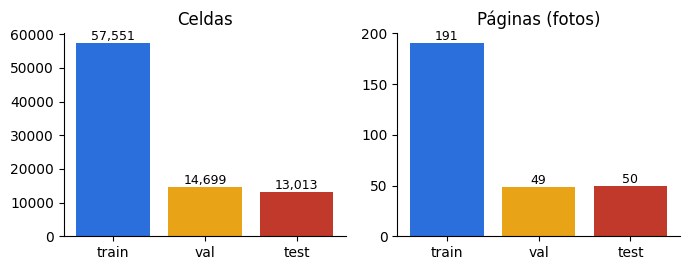

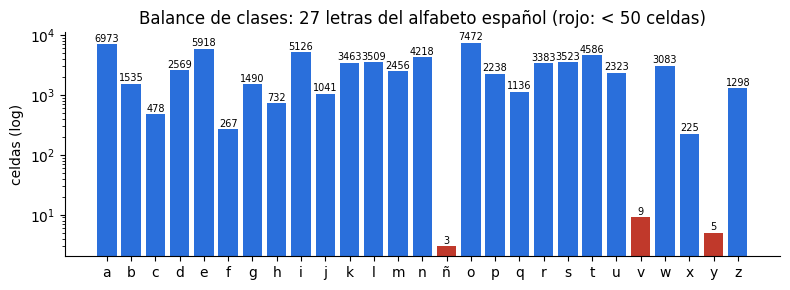

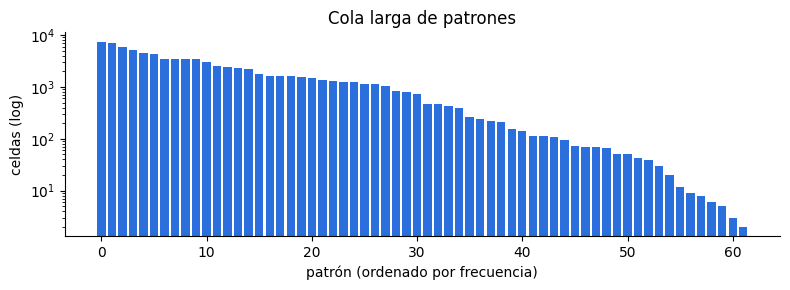

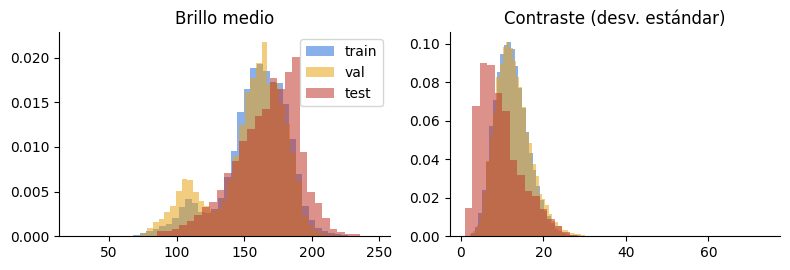

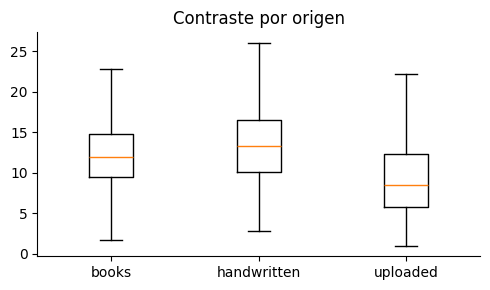

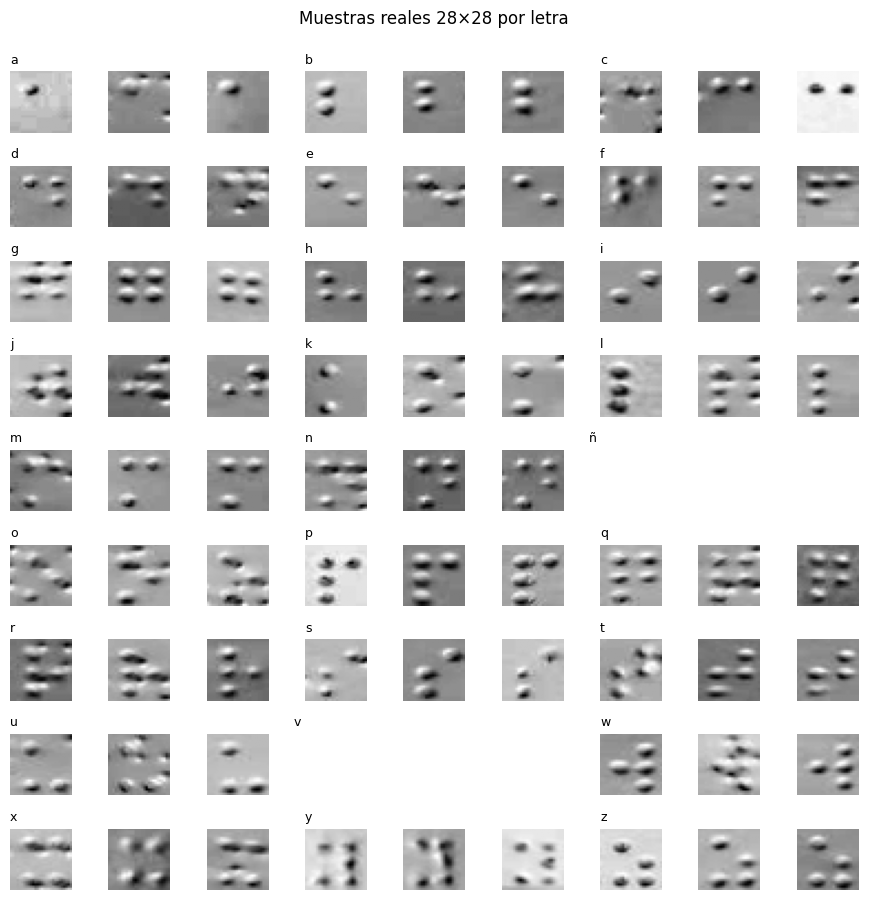

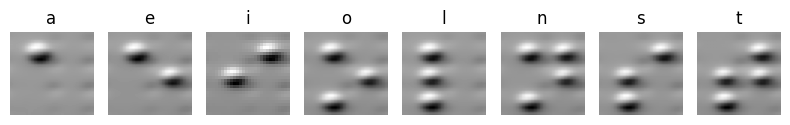

{
 "cells": 85263,
 "patterns": 62,
 "letters": {
  "a": 6973,
  "b": 1535,
  "c": 478,
  "d": 2569,
  "e": 5918,
  "f": 267,
  "g": 1490,
  "h": 732,
  "i": 5126,
  "j": 1041,
  "k": 3463,
  "l": 3509,
  "m": 2456,
  "n": 4218,
  "ñ": 3,
  "o": 7472,
  "p": 2238,
  "q": 1136,
  "r": 3383,
  "s": 3523,
  "t": 4586,
  "u": 2323,
  "v": 9,
  "w": 3083,
  "x": 225,
  "y": 5,
  "z": 1298
 },
 "spanish27_cells": 69059,
 "top5_share_pct": 35.27321346891383,
 "brillo_train": 158.08655171508926,
 "contraste_train": 12.348250223949027,
 "brillo_val": 153.87607210888982,
 "contraste_val": 12.741439928428827,
 "brillo_test": 166.63914843006287,
 "contraste_test": 9.586221033221555,
 "ñ": 3,
 "acentos": {
  "á": 42,
  "é": 1601,
  "í": 12,
  "ó": 20,
  "ú": 1333,
  "ü": 436
 },
 "clases_menos_50": 11
}


In [ ]:
FIG = ROOT / "figures"; C3 = {"train": "#2a6fdb", "val": "#e8a317", "test": "#c0392b"}
cnt = Counter(y_all.tolist()); facts = {"cells": int(len(y_all)), "patterns": len(cnt)}

fig, ax = plt.subplots(1, 2, figsize=(7, 2.8))   # F1
for a_, vals, t in ((ax[0], [int((split_all == s).sum()) for s in C3], "Celdas"), (ax[1], [len(set(page_all[split_all == s])) for s in C3], "Páginas (fotos)")):
    a_.bar(list(C3), vals, color=list(C3.values())); a_.set_title(t)
    for i, v in enumerate(vals): a_.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "f1_particiones.png", dpi=160); plt.show()

vals = [cnt.get(LETTER_TO_PATTERN[c], 0) for c in SPANISH_ALPHABET]   # F2
facts["letters"] = dict(zip(SPANISH_ALPHABET, vals)); facts["spanish27_cells"] = int(sum(vals))
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(SPANISH_ALPHABET, vals, color=["#c0392b" if v < 50 else "#2a6fdb" for v in vals])
ax.set_yscale("log"); ax.set_ylabel("celdas (log)"); ax.set_title("Balance de clases: 27 letras del alfabeto español (rojo: < 50 celdas)")
for i, v in enumerate(vals): ax.text(i, max(v, 1)*1.1, str(v), ha="center", fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "f2_balance_27_letras.png", dpi=160); plt.show()

items = cnt.most_common(); facts["top5_share_pct"] = float(sum(n for _, n in items[:5]) / len(y_all) * 100)  # F3
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(range(len(items)), [n for _, n in items], color="#2a6fdb"); ax.set_yscale("log")
ax.set_xlabel("patrón (ordenado por frecuencia)"); ax.set_ylabel("celdas (log)"); ax.set_title("Cola larga de patrones")
fig.tight_layout(); fig.savefig(FIG / "f3_cola_larga.png", dpi=160); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))   # F4
for s in C3:
    m = split_all == s
    ax[0].hist(X_all[m].mean((1, 2)), bins=40, alpha=.55, color=C3[s], label=s, density=True)
    ax[1].hist(X_all[m].std((1, 2)), bins=40, alpha=.55, color=C3[s], density=True)
    facts[f"brillo_{s}"] = float(X_all[m].mean()); facts[f"contraste_{s}"] = float(X_all[m].std((1, 2)).mean())
ax[0].set_title("Brillo medio"); ax[1].set_title("Contraste (desv. estándar)"); ax[0].legend()
fig.tight_layout(); fig.savefig(FIG / "f4_brillo_contraste.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(5, 3)); gs = ["books", "handwritten", "uploaded"]   # F5
ax.boxplot([X_all[group_all == g].std((1, 2)) for g in gs], tick_labels=gs, showfliers=False); ax.set_title("Contraste por origen")
fig.tight_layout(); fig.savefig(FIG / "f5_boxplot_origen.png", dpi=160); plt.show()

rng = np.random.default_rng(0); fig, axes = plt.subplots(9, 9, figsize=(9, 9))   # F6: 3 muestras x 27 letras
for a_ in axes.ravel(): a_.axis("off")
for k, c in enumerate(SPANISH_ALPHABET):
    idx = np.where((y_all == LETTER_TO_PATTERN[c]) & (split_all == "train"))[0]
    r, col = divmod(k, 3)
    for j, i in enumerate(rng.choice(idx, size=min(3, len(idx)), replace=False) if len(idx) else []):
        axes[r][col*3 + j].imshow(X_all[i], cmap="gray")
    axes[r][col*3].set_title(c, fontsize=9, loc="left")
fig.suptitle("Muestras reales 28×28 por letra", y=0.995); fig.tight_layout(); fig.savefig(FIG / "f6_muestras.png", dpi=160); plt.show()

fig, axes = plt.subplots(1, 8, figsize=(8, 1.6))   # F7
for a_, c in zip(axes, "aeiolnst"):
    a_.imshow(X_all[(y_all == LETTER_TO_PATTERN[c]) & (split_all == "train")].mean(0), cmap="gray"); a_.set_title(c); a_.axis("off")
fig.tight_layout(); fig.savefig(FIG / "f7_imagen_media.png", dpi=160); plt.show()

facts["ñ"] = int(cnt.get(59, 0)); facts["acentos"] = {k: int(cnt.get(v, 0)) for k, v in ACCENT_TO_PATTERN.items()}
facts["clases_menos_50"] = int(sum(n < 50 for _, n in items))
(ROOT / "metrics" / "eda_facts.json").write_text(json.dumps(facts, indent=1, ensure_ascii=False)); print(json.dumps(facts, indent=1, ensure_ascii=False))

## 5. Modelos
* **logreg** (modelo base): regresión logística multinomial sobre 784 píxeles.
* **cnn63**: CNN con cabeza softmax de 63 patrones.
* **cnndots**: CNN con 6 salidas sigmoides (un punto cada una). Comparte evidencia entre patrones y debería generalizar mejor a letras raras (ñ, v, y).

La estandarización por imagen vive **dentro** del modelo para que la app móvil solo envíe píxeles en [0, 1].

In [ ]:
@keras.saving.register_keras_serializable(package="braille")
class PerImageStandardize(layers.Layer):
    def call(self, x):
        m = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
        v = tf.reduce_mean(tf.square(x - m), axis=[1, 2, 3], keepdims=True)
        return (x - m) / (tf.sqrt(v) + 1e-3)

def build_model(kind, augment=False):
    inp = layers.Input((28, 28, 1), name="cell_28x28"); x = inp
    if kind == "logreg":
        x = layers.Flatten()(PerImageStandardize()(x))
        return keras.Model(inp, layers.Dense(63, activation="softmax", kernel_regularizer=keras.regularizers.l2(1e-4))(x), name="logreg")
    if augment:
        x = keras.Sequential([layers.RandomRotation(0.04, fill_mode="nearest"), layers.RandomTranslation(0.08, 0.08, fill_mode="nearest"),
                              layers.RandomZoom(0.08, fill_mode="nearest"), layers.RandomContrast(0.2)], name="augment")(x)
    x = PerImageStandardize()(x)
    for f in (16, 32):
        for _ in range(2):
            x = layers.ReLU()(layers.BatchNormalization()(layers.Conv2D(f, 3, padding="same", use_bias=False)(x)))
        x = layers.MaxPooling2D()(x)
    x = layers.ReLU()(layers.BatchNormalization()(layers.Conv2D(64, 3, padding="same", use_bias=False)(x)))
    x = layers.Dropout(0.3)(layers.Dense(96, activation="relu")(layers.GlobalAveragePooling2D()(x)))
    out = layers.Dense(63, activation="softmax")(x) if kind == "cnn63" else layers.Dense(6, activation="sigmoid")(x)
    return keras.Model(inp, out, name=kind)

def to_patterns(kind, probs):
    if kind in ("logreg", "cnn63"): return probs.argmax(1) + 1, probs.max(1)
    bits = probs > 0.5; empty = ~bits.any(1); bits[empty, probs[empty].argmax(1)] = True
    return (bits * (1 << np.arange(6))).sum(1), np.where(bits, probs, 1 - probs).prod(1)

def to_bits(y): return ((y[:, None] >> np.arange(6)) & 1).astype("float32")

for k in ("logreg", "cnn63", "cnndots"):
    print(k, "parámetros:", build_model(k).count_params())

logreg parámetros: 49455
cnn63 parámetros: 47695
cnndots parámetros: 42166


In [ ]:
Xn = X_all.astype("float32")[..., None] / 255.0
tr, va, te = (split_all == "train"), (split_all == "val"), (split_all == "test")
if QUICK:                      # submuestra solo para la prueba rápida
    sub = np.random.default_rng(0).choice(np.where(tr)[0], 20000, replace=False); tr = np.zeros_like(tr); tr[sub] = True
PRED, TRAIN_INFO = {}, {}

def train_one(kind, seed):
    keras.utils.set_random_seed(seed)
    tgt = (lambda m: to_bits(y_all[m])) if kind == "cnndots" else (lambda m: y_all[m] - 1)
    model = build_model(kind, augment=(kind != "logreg"))
    model.compile(keras.optimizers.Adam(2e-3 if kind == "logreg" else 1e-3),
                  "binary_crossentropy" if kind == "cnndots" else "sparse_categorical_crossentropy")
    t0 = time.time()
    hist = model.fit(Xn[tr], tgt(tr), validation_data=(Xn[va], tgt(va)), epochs=EPOCHS, batch_size=BATCH, verbose=2,
                     callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
                                keras.callbacks.ReduceLROnPlateau(patience=1, factor=0.5)])
    infer = build_model(kind, augment=False); infer.set_weights(model.get_weights())   # sin capas de aumento
    infer.save(ROOT / "models" / f"{kind}_s{seed}.keras")
    out = {}
    for name, m in (("val", va), ("test", te)):
        pat, conf = to_patterns(kind, infer.predict(Xn[m], batch_size=1024, verbose=0))
        out[name] = dict(true=y_all[m], pred=pat, conf=conf, page=page_all[m])
    PRED[(kind, seed)] = out
    TRAIN_INFO[(kind, seed)] = dict(params=int(infer.count_params()), epochs=len(hist.history["loss"]), seconds=round(time.time() - t0, 1))
    print(kind, seed, TRAIN_INFO[(kind, seed)])

for s in SEEDS:
    for k in ("logreg", "cnn63", "cnndots"):
        train_one(k, s)

Epoch 1/12
225/225 - 6s - 25ms/step - loss: 0.5037 - val_loss: 0.1810 - learning_rate: 0.0020
Epoch 2/12
225/225 - 1s - 3ms/step - loss: 0.1794 - val_loss: 0.1490 - learning_rate: 0.0020
Epoch 3/12
225/225 - 1s - 6ms/step - loss: 0.1539 - val_loss: 0.1415 - learning_rate: 0.0020
Epoch 4/12
225/225 - 1s - 3ms/step - loss: 0.1425 - val_loss: 0.1394 - learning_rate: 0.0020
Epoch 5/12
225/225 - 1s - 3ms/step - loss: 0.1358 - val_loss: 0.1393 - learning_rate: 0.0020
Epoch 6/12
225/225 - 1s - 4ms/step - loss: 0.1314 - val_loss: 0.1400 - learning_rate: 0.0020
Epoch 7/12
225/225 - 2s - 8ms/step - loss: 0.1187 - val_loss: 0.1318 - learning_rate: 0.0010
Epoch 8/12
225/225 - 1s - 5ms/step - loss: 0.1160 - val_loss: 0.1322 - learning_rate: 0.0010
Epoch 9/12
225/225 - 1s - 4ms/step - loss: 0.1101 - val_loss: 0.1293 - learning_rate: 5.0000e-04
Epoch 10/12
225/225 - 1s - 3ms/step - loss: 0.1089 - val_loss: 0.1294 - learning_rate: 5.0000e-04
Epoch 11/12
225/225 - 1s - 4ms/step - loss: 0.1058 - val_los

## 6. Evaluación (secciones 19–20)
Todas las métricas son **macro** (promedio por clase, sensible a clases raras) sobre las **50 páginas de prueba subidas por usuarios**, que nunca se usaron para decidir nada.
* `todas`: todas las celdas de prueba.
* `español-27`: solo celdas cuya letra verdadera es del alfabeto español; predecir un patrón fuera de las 27 letras cuenta como error.

In [ ]:
def prf(y, p, labels):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=labels, average="macro", zero_division=0)
    return dict(accuracy=float((y == p).mean()), precision=float(pr), recall=float(rc), f1=float(f1))

def metrics(y, p, universe):
    if universe == "español-27":
        m = np.isin(y, SPANISH_PATTERNS); y, p = y[m], p[m]
    return dict(n=int(len(y)), clases=len(set(y.tolist())), **prf(y, p, sorted(set(y.tolist()))))

def mcnemar(y, pa, pb):
    ra, rb = pa == y, pb == y; b, c = int((ra & ~rb).sum()), int((~ra & rb).sum())
    stat = (abs(b - c) - 1) ** 2 / max(b + c, 1)
    return dict(solo_A_acierta=b, solo_B_acierta=c, chi2=float(stat), p_valor=float(chi2.sf(stat, 1)))

def boot_pages(y, pa, pb, pages, n=1000, seed=0):
    up = np.unique(pages); rng = np.random.default_rng(seed)
    ca = np.array([(pa[pages == u] == y[pages == u]).sum() for u in up]); cb = np.array([(pb[pages == u] == y[pages == u]).sum() for u in up])
    nn = np.array([(pages == u).sum() for u in up]); D = []
    for _ in range(n):
        s = rng.integers(0, len(up), len(up)); D.append(ca[s].sum() / nn[s].sum() - cb[s].sum() / nn[s].sum())
    return [float(np.percentile(D, 2.5)), float(np.percentile(D, 97.5))]

MODELS = ("logreg", "cnn63", "cnndots"); NAMES = {"logreg": "Regresión logística (base)", "cnn63": "CNN 63 clases", "cnndots": "CNN 6 puntos"}
rows = []
for part in ("val", "test"):
    for u in ("todas", "español-27"):
        for k in MODELS:
            runs = [metrics(PRED[(k, s)][part]["true"], PRED[(k, s)][part]["pred"], u) for s in SEEDS]
            row = dict(partición=part, universo=u, modelo=NAMES[k], n=runs[0]["n"], clases=runs[0]["clases"])
            for met in ("accuracy", "precision", "recall", "f1"):
                v = [r[met] for r in runs]; row[met] = f"{np.mean(v):.4f} ± {np.std(v):.4f}"
            rows.append(row)
RES = pd.DataFrame(rows); RES.to_csv(ROOT / "metrics" / "tabla_metricas.csv", index=False)
print("=== PRUEBA (50 páginas reales no vistas) ==="); display(RES[RES.partición == "test"].drop(columns="partición"))

s0 = SEEDS[0]; tt = {}
for cnn in ("cnn63", "cnndots"):
    d = PRED[(cnn, s0)]["test"]; b = PRED[("logreg", s0)]["test"]
    tt[f"{cnn}_vs_logreg"] = dict(mcnemar=mcnemar(d["true"], d["pred"], b["pred"]), ic95_dif_accuracy=boot_pages(d["true"], d["pred"], b["pred"], d["page"]))
d1, d2 = PRED[("cnndots", s0)]["test"], PRED[("cnn63", s0)]["test"]
tt["cnndots_vs_cnn63"] = dict(mcnemar=mcnemar(d1["true"], d1["pred"], d2["pred"]), ic95_dif_accuracy=boot_pages(d1["true"], d1["pred"], d2["pred"], d1["page"]))
(ROOT / "metrics" / "pruebas_estadisticas.json").write_text(json.dumps(tt, indent=1, ensure_ascii=False)); print(json.dumps(tt, indent=1, ensure_ascii=False))

=== PRUEBA (50 páginas reales no vistas) ===


,universo,modelo,n,clases,accuracy,precision,recall,f1
6,todas,Regresión logística (base),13013,61,0.3450 ± 0.0005,0.2702 ± 0.0011,0.2398 ± 0.0025,0.2189 ± 0.0007
7,todas,CNN 63 clases,13013,61,0.8140 ± 0.0397,0.7052 ± 0.0285,0.7028 ± 0.0338,0.6796 ± 0.0364
8,todas,CNN 6 puntos,13013,61,0.8569 ± 0.0287,0.7317 ± 0.0308,0.8252 ± 0.0397,0.7498 ± 0.0371
9,español-27,Regresión logística (base),9628,26,0.3413 ± 0.0029,0.4696 ± 0.0036,0.2598 ± 0.0018,0.3104 ± 0.0032
10,español-27,CNN 63 clases,9628,26,0.8208 ± 0.0443,0.8003 ± 0.0273,0.7345 ± 0.0361,0.7564 ± 0.0377
11,español-27,CNN 6 puntos,9628,26,0.8507 ± 0.0326,0.8512 ± 0.0252,0.8308 ± 0.0353,0.8308 ± 0.0309


{
 "cnn63_vs_logreg": {
  "mcnemar": {
   "solo_A_acierta": 6641,
   "solo_B_acierta": 149,
   "chi2": 6205.166568483063,
   "p_valor": 0.0
  },
  "ic95_dif_accuracy": [
   0.4356251075269302,
   0.5578859072657941
  ]
 },
 "cnndots_vs_logreg": {
  "mcnemar": {
   "solo_A_acierta": 6450,
   "solo_B_acierta": 306,
   "chi2": 5585.620041444642,
   "p_valor": 0.0
  },
  "ic95_dif_accuracy": [
   0.41338488649916594,
   0.5296296345958558
  ]
 },
 "cnndots_vs_cnn63": {
  "mcnemar": {
   "solo_A_acierta": 647,
   "solo_B_acierta": 995,
   "chi2": 73.33069427527406,
   "p_valor": 1.0964941472501552e-17
  },
  "ic95_dif_accuracy": [
   -0.04311355727373731,
   -0.01199880574061583
  ]
 }
}


Mejor CNN según F1 macro en VALIDACIÓN: cnndots


,letra,soporte,precision,recall,f1
0,a,986,0.792,0.963,0.869
12,o,939,0.923,0.668,0.775
10,e,868,0.945,0.825,0.881
5,i,748,0.935,0.805,0.865
18,t,612,0.975,0.776,0.864
17,n,608,0.988,0.688,0.811
8,s,475,0.868,0.773,0.817
13,r,471,0.942,0.730,0.823
3,l,439,0.737,0.902,0.811
24,w,405,0.975,0.849,0.908


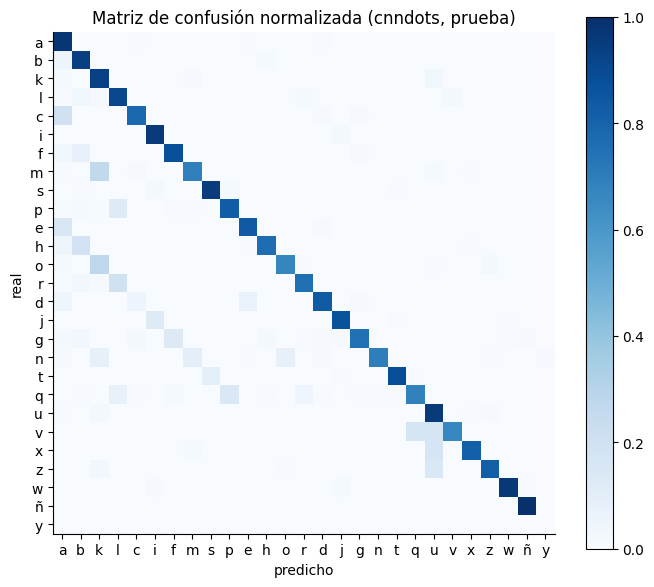

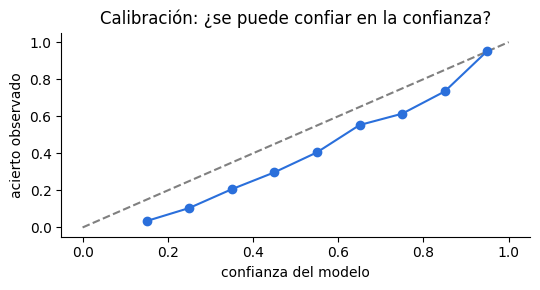

confianza >= 0.6: cubre 89.4% de celdas, exactitud 87.55%
confianza >= 0.9: cubre 66.6% de celdas, exactitud 95.26%


In [ ]:
# Rendimiento por letra española (mejor CNN en prueba) y matriz de confusión
best = max(("cnn63", "cnndots"), key=lambda k: np.mean([metrics(PRED[(k, s)]["val"]["true"], PRED[(k, s)]["val"]["pred"], "todas")["f1"] for s in SEEDS]))
print("Mejor CNN según F1 macro en VALIDACIÓN:", best)
d = PRED[(best, s0)]["test"]; y, p = d["true"], d["pred"]
pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=SPANISH_PATTERNS, zero_division=0)
PER = pd.DataFrame({"letra": [PATTERN_TO_LETTER[q] for q in SPANISH_PATTERNS], "soporte": sup, "precision": pr, "recall": rc, "f1": f1}).sort_values("soporte", ascending=False)
PER.to_csv(ROOT / "metrics" / "por_letra.csv", index=False); display(PER.round(3))

m = np.isin(y, SPANISH_PATTERNS) & np.isin(p, SPANISH_PATTERNS); cm = confusion_matrix(y[m], p[m], labels=SPANISH_PATTERNS)
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
L = [PATTERN_TO_LETTER[q] for q in SPANISH_PATTERNS]; ax.set_xticks(range(27), L); ax.set_yticks(range(27), L)
ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(f"Matriz de confusión normalizada ({best}, prueba)"); fig.colorbar(im)
fig.tight_layout(); fig.savefig(FIG / "f8_confusion.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 3))      # curva de aprendizaje no disponible → calibración de confianza
conf = d["conf"]; ok = (p == y); bins = np.linspace(0, 1, 11); xs, ys = [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mk = (conf >= lo) & (conf < hi + 1e-9)
    if mk.sum() > 20: xs.append((lo + hi) / 2); ys.append(ok[mk].mean())
ax.plot([0, 1], [0, 1], "--", color="gray"); ax.plot(xs, ys, "o-", color="#2a6fdb"); ax.set_xlabel("confianza del modelo"); ax.set_ylabel("acierto observado")
ax.set_title("Calibración: ¿se puede confiar en la confianza?"); fig.tight_layout(); fig.savefig(FIG / "f9_calibracion.png", dpi=160); plt.show()
for th in (0.6, 0.9):
    mk = conf >= th; print(f"confianza >= {th}: cubre {mk.mean()*100:.1f}% de celdas, exactitud {ok[mk].mean()*100:.2f}%")

## 7. Por qué NO usamos solo el dataset de Kaggle (26 letras)
El conjunto «Braille Character Dataset» se genera a partir de **una imagen base por letra** con 60 aumentos (3 familias × 20). Una partición aleatoria pone variantes de la misma imagen en entrenamiento y prueba. La demostración compara esa partición con «dejar una familia de aumento fuera».

In [ ]:
KG = ROOT / "BrailleCNN"
if not KG.exists():
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/Shanks0465/BrailleCNN.git", str(KG)], check=True)
    with zipfile.ZipFile(KG / "Braille_Dataset.zip") as z: z.extractall(KG / "ds")
folder = next((KG / "ds").rglob("*0whs.jpg")).parent
Xk, yk, fk = [], [], []
for f in sorted(folder.glob("*.jpg")):
    mt = re.match(r"([a-z])1\.JPG\d+(\w+)\.jpg", f.name)
    if mt: Xk.append(np.asarray(Image.open(f).convert("L").resize((28, 28)), dtype="float32") / 255.0); yk.append(ord(mt.group(1)) - 97); fk.append(mt.group(2))
Xk, yk, fk = np.stack(Xk), np.array(yk), np.array(fk)

def small_cnn(Xa, ya, Xb, yb, seed=1, ep=15):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([layers.Input((28, 28, 1)), layers.Conv2D(16, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
                          layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(), layers.Flatten(),
                          layers.Dense(64, activation="relu"), layers.Dense(26, activation="softmax")])
    m.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"]); m.fit(Xa[..., None], ya, epochs=ep, batch_size=32, verbose=0)
    return float(m.evaluate(Xb[..., None], yb, verbose=0)[1])

kg = {"imagenes": int(len(yk)), "clases": int(len(set(yk))), "familias": {f: int((fk == f).sum()) for f in sorted(set(fk))}}
a, b = train_test_split(np.arange(len(yk)), test_size=0.3, stratify=yk, random_state=0)
kg["particion_aleatoria"] = dict(logreg=float(LogisticRegression(max_iter=2000).fit(Xk[a].reshape(len(a), -1), yk[a]).score(Xk[b].reshape(len(b), -1), yk[b])), cnn=small_cnn(Xk[a], yk[a], Xk[b], yk[b]))
kg["dejar_una_familia_fuera"] = {}
for held in sorted(set(fk)):
    a, b = np.where(fk != held)[0], np.where(fk == held)[0]
    kg["dejar_una_familia_fuera"][held] = dict(logreg=float(LogisticRegression(max_iter=2000).fit(Xk[a].reshape(len(a), -1), yk[a]).score(Xk[b].reshape(len(b), -1), yk[b])), cnn=small_cnn(Xk[a], yk[a], Xk[b], yk[b]))
(ROOT / "metrics" / "kaggle_fuga.json").write_text(json.dumps(kg, indent=1)); print(json.dumps(kg, indent=1))

{
 "imagenes": 1560,
 "clases": 26,
 "familias": {
  "dim": 520,
  "rot": 520,
  "whs": 520
 },
 "particion_aleatoria": {
  "logreg": 0.717948717948718,
  "cnn": 0.7820512652397156
 },
 "dejar_una_familia_fuera": {
  "dim": {
   "logreg": 0.13846153846153847,
   "cnn": 0.33076924085617065
  },
  "rot": {
   "logreg": 0.2865384615384615,
   "cnn": 0.32307693362236023
  },
  "whs": {
   "logreg": 0.1673076923076923,
   "cnn": 0.2461538463830948
  }
 }
}


## 8. Exportar a TensorFlow Lite para la app Flutter
Se exporta el mejor modelo según validación, se verifica que TFLite predice igual que Keras y se mide tamaño y latencia (en la CPU de Colab; la latencia en el teléfono debe medirse con la app).

In [ ]:
def run_tflite(blob, X, kind, n=None):
    it = tf.lite.Interpreter(model_content=blob, num_threads=2); it.allocate_tensors()
    i, o = it.get_input_details()[0], it.get_output_details()[0]; n = len(X) if n is None else min(n, len(X))
    outs = np.zeros((n, o["shape"][-1]), "float32"); t0 = time.perf_counter()
    for k in range(n): it.set_tensor(i["index"], X[k:k+1]); it.invoke(); outs[k] = it.get_tensor(o["index"])[0]
    return to_patterns(kind, outs)[0], (time.perf_counter() - t0) / n * 1000

keras_model = keras.saving.load_model(ROOT / "models" / f"{best}_s{s0}.keras")
Xte, yte = Xn[te], y_all[te]; kp = to_patterns(best, keras_model.predict(Xte, batch_size=1024, verbose=0))[0]
tfl = {"modelo": best, "semilla": s0, "keras": prf(yte, kp, sorted(set(yte.tolist())))}
variants = {}
c = tf.lite.TFLiteConverter.from_keras_model(keras_model); variants["float32"] = c.convert()
c = tf.lite.TFLiteConverter.from_keras_model(keras_model); c.optimizations = [tf.lite.Optimize.DEFAULT]; variants["pesos_int8_dinamico"] = c.convert()
for name, blob in variants.items():
    pr_, ms = run_tflite(blob, Xte, best)
    tfl[name] = dict(size_kb=round(len(blob) / 1024, 1), **prf(yte, pr_, sorted(set(yte.tolist()))), coincide_con_keras=float((pr_ == kp).mean()), latencia_ms_por_celda_cpu_colab=round(ms, 3))
    (ROOT / "models" / f"{best}_{name}.tflite").write_bytes(blob)
(ROOT / "metrics" / "tflite.json").write_text(json.dumps(tfl, indent=1)); print(json.dumps(tfl, indent=1))

A = ROOT / "app_assets"; (A / "models").mkdir(exist_ok=True)
(A / "models" / "braille_cells.tflite").write_bytes(variants["float32"])
(A / "models" / "model_meta.json").write_text(json.dumps({"kind": best, "input": [1, 28, 28, 1], "range": [0, 1]}))
(A / "spanish_braille.json").write_text(json.dumps({"letters": {str(p): c for p, c in PATTERN_TO_LETTER.items()}, "accents": {str(p): c for p, c in PATTERN_TO_ACCENT.items()},
    "digits": {str(p): d for p, d in PATTERN_TO_DIGIT.items()}, "capital_sign": CAPITAL_SIGN, "number_sign": NUMBER_SIGN}, ensure_ascii=False))
print("Archivos para la app:", [str(p.relative_to(A)) for p in A.rglob("*") if p.is_file()])

Saved artifact at '/tmp/tmpc75z1hgz'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='cell_28x28')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  137018449691664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775655248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775653904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137018449698960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775662544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775653136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775655632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775655440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775655824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775654096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137017775655056: T

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


{
 "modelo": "cnndots",
 "semilla": 1,
 "keras": {
  "accuracy": 0.8168754322600477,
  "precision": 0.6880896097498629,
  "recall": 0.7765199348744033,
  "f1": 0.6983883844744007
 },
 "float32": {
  "size_kb": 170.0,
  "accuracy": 0.8167985860293553,
  "precision": 0.6879442313547582,
  "recall": 0.7764229322553325,
  "f1": 0.6982428665948064,
  "coincide_con_keras": 0.9999231537693076,
  "latencia_ms_por_celda_cpu_colab": 0.255
 },
 "pesos_int8_dinamico": {
  "size_kb": 53.7,
  "accuracy": 0.8162606624145086,
  "precision": 0.6919186898156374,
  "recall": 0.7751014761436235,
  "f1": 0.7007184648214573,
  "coincide_con_keras": 0.9860908322446784,
  "latencia_ms_por_celda_cpu_colab": 0.224
 }
}
Archivos para la app: ['spanish_braille.json', 'models/model_meta.json', 'models/braille_cells.tflite']


## 9. Demostración rápida: de celdas reales a texto en español

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


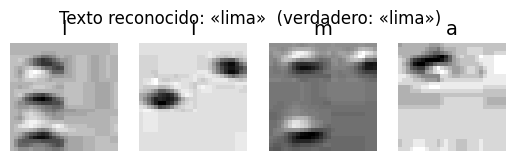

In [ ]:
# Toma celdas reales de prueba que forman una palabra y las traduce con el modelo exportado (flujo de la app)
word = "lima"
rng = np.random.default_rng(7); cells, truth = [], []
for ch in word:
    idx = np.where((y_all == LETTER_TO_PATTERN[ch]) & te)[0]; i = int(rng.choice(idx)); cells.append(Xn[i:i+1]); truth.append(LETTER_TO_PATTERN[ch])
pred, _ = run_tflite(variants["float32"], np.concatenate(cells), best)
fig, axes = plt.subplots(1, len(word), figsize=(1.6 * len(word), 1.8))
for a_, c_, pp in zip(axes, cells, pred): a_.imshow(c_[0, ..., 0], cmap="gray"); a_.set_title(decode([pp]), fontsize=14); a_.axis("off")
plt.suptitle(f"Texto reconocido: «{decode(pred)}»  (verdadero: «{word}»)"); plt.show()

## 10. Empaquetar resultados y descargar

In [ ]:
ZIP = ROOT / "braille_resultados.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in ("metrics", "figures", "app_assets"):
        for f in (ROOT / sub).rglob("*"):
            if f.is_file(): z.write(f, f.relative_to(ROOT))
    for f in (ROOT / "models").glob("*.tflite"): z.write(f, f.relative_to(ROOT))
print("Generado:", ZIP, f"({ZIP.stat().st_size/1e6:.1f} MB)")
try:
    from google.colab import files; files.download(str(ZIP))
except ImportError:
    print("(Fuera de Colab: el zip queda en la carpeta indicada)")

Generado: /content/braille/braille_resultados.zip (0.7 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>